<a href="https://colab.research.google.com/github/a01254189-max/Evidences_2039_2026/blob/main/NFL_Combine_Presentacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 0. Índice — Presentación NFL Combine

**Tema:** Peso corporal, posición y velocidad en la prueba de 40 yardas.

Esta presentación sigue exactamente la secuencia solicitada. Haz clic para avanzar a cada sección y usa **↩ Volver al índice** para regresar.

| Sección | Contenido | Acceso directo |
|:--|:--|:--|
| **1** | Título y objetivo | [Ir al título](#scrollTo=titulo) |
| **2** | Descripción de la base de datos | [Ir al dataset](#scrollTo=dataset) |
| **3** | Descripción de las variables | [Ir a variables](#scrollTo=variables) |
| **4** | Pregunta 1 → gráfica de dispersión → 2 insights | [Ir al estudio 1](#scrollTo=pregunta1) · [Ver gráfica 1](#scrollTo=grafica1) |
| **5** | Pregunta 2 → diagrama de cajas → 2 insights | [Ir al estudio 2](#scrollTo=pregunta2) · [Ver gráfica 2](#scrollTo=grafica2) |

**Para ejecutar:** selecciona **Entorno de ejecución → Ejecutar todas**. Los números y hallazgos se actualizan automáticamente con los datos descargados.

> **Alcance:** esta entrega incluye exactamente **2 preguntas y 2 gráficas**. Las 8 preguntas corresponden a la futura presentación final, según las instrucciones del profesor.

# 1. Peso, posición y velocidad: ¿qué revelan las 40 yardas del NFL Combine?

**Objetivo:** investigar si el **peso corporal** se relaciona con el **tiempo de la carrera de 40 yardas** y si ese tiempo cambia según la **posición** del jugador.

🏈 **Idea clave:** en esta prueba, **menos segundos significa mayor velocidad**.

[↩ Volver al índice](#scrollTo=indice) · [Siguiente: dataset →](#scrollTo=dataset)

### Preparación técnica — Librerías y descarga automática

Este código permite reproducir las gráficas. Al presentar, enfócate en la interpretación de las secciones, no en explicar línea por línea.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, linregress
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", context="talk")
pd.set_option("display.max_columns", 30)

url = "https://github.com/nflverse/nflverse-data/releases/download/combine/combine.csv"
try:
    df = pd.read_csv(url)
except Exception as exc:
    raise RuntimeError("No se pudo descargar el CSV. Verifica la conexión a internet en Colab.") from exc

required = {"season", "pos", "wt", "forty"}
missing = required.difference(df.columns)
if missing:
    raise ValueError(f"Faltan columnas necesarias: {sorted(missing)}")

print("✅ Base NFL Combine cargada correctamente")
print(f"Registros originales: {len(df):,} | Variables originales: {df.shape[1]}")

✅ Base NFL Combine cargada correctamente
Registros originales: 8,968 | Variables originales: 18


# 2. Descripción del dataset

| Aspecto | Explicación sencilla |
|:--|:--|
| **Fuente** | [nflverse — NFL Combine](https://github.com/nflverse/nflverse-data/releases/tag/combine), con resultados históricos procedentes de Pro Football Reference. |
| **Tipo de datos** | Resultados de pruebas físicas y medidas corporales de participantes del *NFL Scouting Combine*. |
| **Contexto** | El Combine es una evaluación de prospectos de fútbol americano que incluye la prueba de velocidad de **40 yardas**. |
| **Una fila** | Un registro de **un jugador** evaluado en una edición del Combine. |
| **Una columna** | Una característica del jugador o una medición de una prueba, como peso, posición o tiempo. |

La siguiente celda muestra **el número real de observaciones, variables y años** de la versión descargada.

[↩ Volver al índice](#scrollTo=indice) · [Siguiente: variables →](#scrollTo=variables)

In [3]:
anios = pd.to_numeric(df["season"], errors="coerce").dropna()
periodo = f"{int(anios.min())}–{int(anios.max())}" if not anios.empty else "No disponible"
resumen_dataset = pd.DataFrame({
    "Indicador": ["Observaciones (filas)", "Variables (columnas)", "Periodo cubierto", "Unidad de observación"],
    "Valor": [f"{len(df):,}", f"{df.shape[1]}", periodo, "1 jugador en 1 edición del Combine"],
})
display(resumen_dataset)

,Indicador,Valor
0,Observaciones (filas),"8,968"
1,Variables (columnas),18
2,Periodo cubierto,2000–2026
3,Unidad de observación,1 jugador en 1 edición del Combine


# 3. Descripción de las variables de interés

**No analizamos todas las columnas:** usamos estas **3 variables** porque permiten responder nuestras dos preguntas.

| Variable en Python | ¿Qué significa? | Tipo | Unidad / categorías |
|:--|:--|:--|:--|
| **`wt`** | **Peso corporal** del jugador. Es lo que pesa durante la evaluación. | Numérica | Libras (**lb**). Ej.: 200 lb ≈ 90.7 kg. |
| **`forty`** | **Tiempo que tarda en correr 40 yardas** (aprox. 36.6 metros). Un valor menor representa un corredor más rápido. | Numérica | Segundos (**s**). Ej.: 4.50 s. |
| **`pos`** | **Posición del jugador** dentro del campo; clasifica a los participantes por rol. | Categórica | Ej.: **CB, WR, RB, QB, OT**, etc. |

**Cómo leer las gráficas:**

- **Gráfica 1:** eje X = `wt` (peso en libras); eje Y = `forty` (tiempo en segundos).
- **Gráfica 2:** eje X = `pos` (posición); eje Y = `forty` (tiempo en segundos). Se comparan los rangos de tiempo entre posiciones.

**Abreviaturas de posiciones:** CB = *cornerback* (esquinero); WR = *wide receiver* (receptor); RB = *running back* (corredor); S = *safety*; OLB = *outside linebacker*; TE = *tight end* (ala cerrada); QB = *quarterback* (mariscal de campo); DE = *defensive end*; DT = *defensive tackle*; OT = *offensive tackle*.

[↩ Volver al índice](#scrollTo=indice) · [Siguiente: pregunta 1 →](#scrollTo=pregunta1)

### Preparación de variables para el análisis

Quitamos registros sin peso, tiempo o posición válidos. **No inventamos valores** para los datos faltantes.

In [4]:
columns = ["season", "pos", "wt", "forty"]
if "player_name" in df.columns:
    columns.insert(1, "player_name")

data = df[columns].copy()
data["wt"] = pd.to_numeric(data["wt"], errors="coerce")
data["forty"] = pd.to_numeric(data["forty"], errors="coerce")
data["pos"] = data["pos"].astype("string").str.strip().str.upper()

clean = data.dropna(subset=["wt", "forty", "pos"])
clean = clean[(clean["wt"] > 0) & (clean["forty"] > 0)].copy()
if len(clean) < 30:
    raise ValueError("Hay pocos registros válidos para realizar el análisis.")

print(f"Registros con peso, 40 yardas y posición válidos: {len(clean):,}")
print("Recuerda: tiempo más bajo = mayor velocidad.")

Registros con peso, 40 yardas y posición válidos: 8,028
Recuerda: tiempo más bajo = mayor velocidad.


# 4. Pregunta de investigación 1

### ¿Qué relación existe entre el peso corporal y el tiempo de las 40 yardas?

**Estudio:** comparar `wt` (peso) con `forty` (tiempo) usando un **diagrama de dispersión**, una línea de tendencia y una correlación.

**Qué buscamos:** saber si los jugadores más pesados suelen registrar tiempos mayores o menores.

[↩ Volver al índice](#scrollTo=indice) · [Ver gráfica 1 →](#scrollTo=grafica1)

## Estudio / Gráfica 1 — Peso vs. tiempo

Cada punto es un registro de un participante. La línea roja resume la tendencia general.

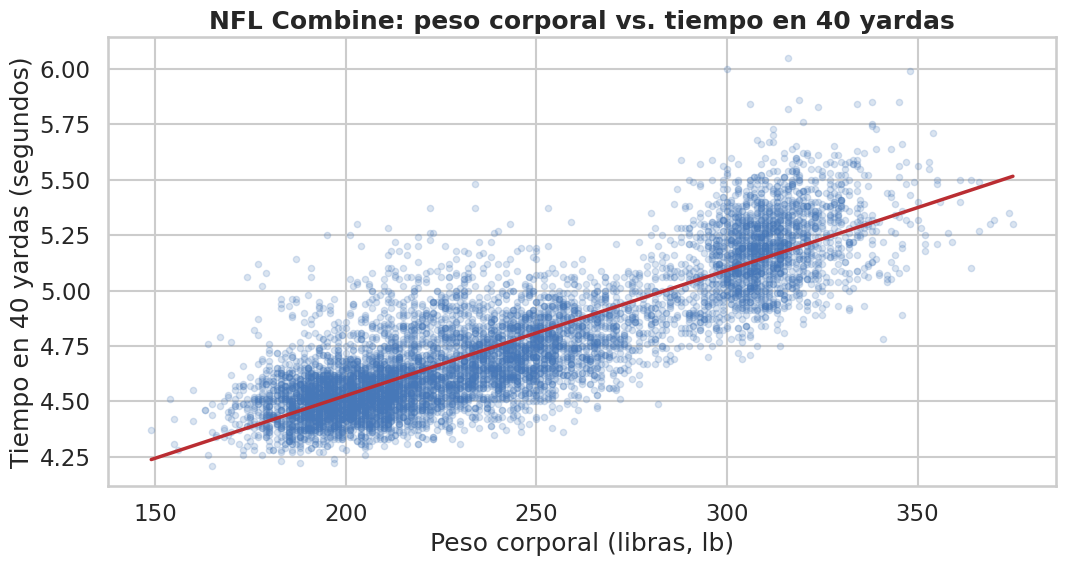

In [5]:
fig, ax = plt.subplots(figsize=(11, 6))
sns.regplot(
    data=clean, x="wt", y="forty", ax=ax, ci=None,
    scatter_kws={"alpha": 0.20, "s": 20, "color": "#4778B8"},
    line_kws={"color": "#BA2D32", "linewidth": 2.5}
)
ax.set_title("NFL Combine: peso corporal vs. tiempo en 40 yardas", weight="bold", fontsize=18)
ax.set_xlabel("Peso corporal (libras, lb)")
ax.set_ylabel("Tiempo en 40 yardas (segundos)")
plt.tight_layout()
plt.show()

r, p = pearsonr(clean["wt"], clean["forty"])
reg = linregress(clean["wt"], clean["forty"])

### Insights de la gráfica 1 (máximo 2)

Los resultados de abajo se generan automáticamente para evitar inventar números.

In [6]:
sentido = "positiva" if r > 0.05 else "negativa" if r < -0.05 else "muy débil"
cambio_diez = reg.slope * 10
display(Markdown(
    f"**1.** La relación entre peso y tiempo es **{sentido}** (correlación de Pearson: **r = {r:.2f}**). "
    f"En el conjunto de datos, los puntos muestran la tendencia general entre ambas variables.\n\n"
    f"**2.** Según la línea de tendencia, una diferencia de **10 lb** se asocia con "
    f"**{abs(cambio_diez):.3f} segundos {'más' if cambio_diez >= 0 else 'menos'}** en el tiempo estimado. "
    f"Esto describe una asociación, **no prueba causalidad**."
))

**1.** La relación entre peso y tiempo es **positiva** (correlación de Pearson: **r = 0.85**). En el conjunto de datos, los puntos muestran la tendencia general entre ambas variables.

**2.** Según la línea de tendencia, una diferencia de **10 lb** se asocia con **0.057 segundos más** en el tiempo estimado. Esto describe una asociación, **no prueba causalidad**.

# 5. Pregunta de investigación 2

### ¿Cómo cambian los tiempos de las 40 yardas según la posición del jugador?

**Estudio:** comparar `forty` entre categorías de `pos` mediante un **diagrama de cajas** (*boxplot*).

**Cómo leerlo:** la línea dentro de cada caja es la **mediana** (el tiempo central). Una mediana más baja implica mayor velocidad típica en esa posición. Las cajas muestran la variación de tiempos.

[↩ Volver al índice](#scrollTo=indice) · [Ver gráfica 2 →](#scrollTo=grafica2)

## Estudio / Gráfica 2 — Tiempos por posición

Se comparan posiciones frecuentes con suficientes registros para que las diferencias sean más fáciles de observar.

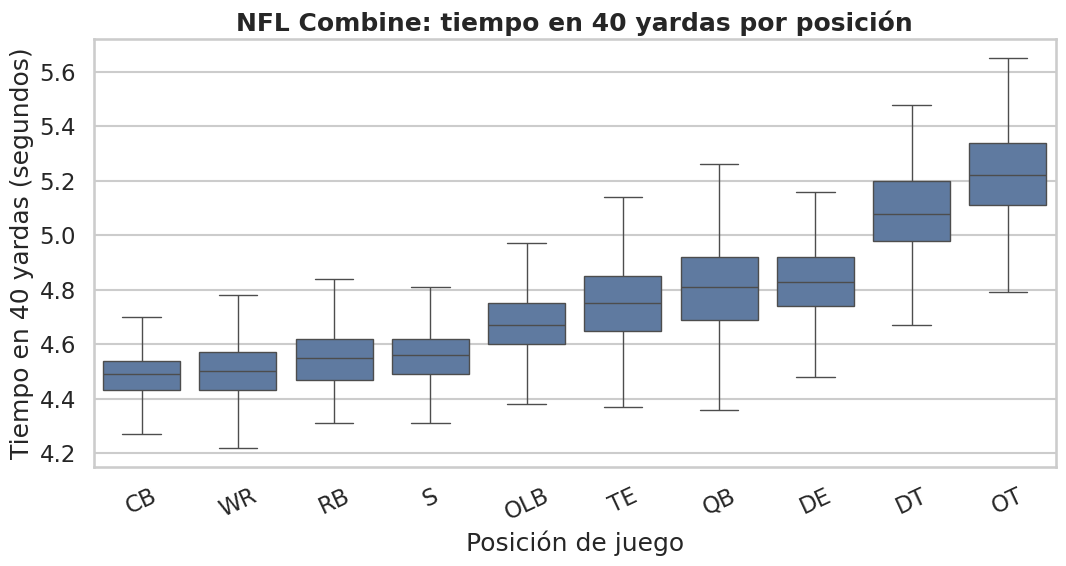

,jugadores,mediana_s,promedio_s,peso_promedio_lb
pos,,,,
CB,837,4.49,4.49,192.62
WR,1159,4.50,4.51,201.02
RB,717,4.55,4.55,213.10
S,520,4.56,4.56,207.11
OLB,428,4.67,4.68,240.37
TE,452,4.75,4.76,252.95
QB,413,4.81,4.81,222.18
DE,514,4.83,4.83,268.66
DT,545,5.08,5.09,306.79


In [7]:
posiciones_objetivo = ["CB", "WR", "RB", "S", "OLB", "TE", "QB", "DE", "DT", "OT"]
conteos = clean["pos"].value_counts()
selected = [p for p in posiciones_objetivo if conteos.get(p, 0) >= 30]
if len(selected) < 3:
    selected = conteos[conteos >= 30].head(10).index.tolist()
if len(selected) < 2:
    raise ValueError("No hay suficientes posiciones para comparar.")

positions_df = clean[clean["pos"].isin(selected)].copy()
position_stats = (
    positions_df.groupby("pos")
    .agg(jugadores=("forty", "size"), mediana_s=("forty", "median"),
         promedio_s=("forty", "mean"), peso_promedio_lb=("wt", "mean"))
    .sort_values("mediana_s")
)
orden = position_stats.index.tolist()

fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(data=positions_df, x="pos", y="forty", order=orden,
            ax=ax, color="#5478AB", showfliers=False)
ax.set_title("NFL Combine: tiempo en 40 yardas por posición", weight="bold", fontsize=18)
ax.set_xlabel("Posición de juego")
ax.set_ylabel("Tiempo en 40 yardas (segundos)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

display(position_stats.round(2))

### Insights de la gráfica 2 (máximo 2)

Las posiciones más rápida y más lenta se identifican por su **mediana**, no por una sola observación excepcional.

In [8]:
rapida = position_stats.iloc[0]
lenta = position_stats.iloc[-1]
display(Markdown(
    f"**1.** Entre las posiciones comparadas, **{position_stats.index[0]}** registra la menor mediana "
    f"(**{rapida['mediana_s']:.2f} s**), por lo que su desempeño típico es el más rápido.\n\n"
    f"**2.** **{position_stats.index[-1]}** registra la mayor mediana "
    f"(**{lenta['mediana_s']:.2f} s**), lo que indica un tiempo típico más alto en esta prueba."
))

**1.** Entre las posiciones comparadas, **CB** registra la menor mediana (**4.49 s**), por lo que su desempeño típico es el más rápido.

**2.** **OT** registra la mayor mediana (**5.22 s**), lo que indica un tiempo típico más alto en esta prueba.

## Cierre

**Conclusión:** tanto el peso corporal como la posición de juego **están asociados** con los tiempos de las 40 yardas. Sin embargo, no significa que el peso sea la única causa de las diferencias: el tipo de jugador y otros factores también pueden intervenir.

**Fuentes:** [nflverse — descarga del Combine](https://github.com/nflverse/nflverse-data/releases/tag/combine) · [Diccionario de variables](https://nflreadr.nflverse.com/articles/dictionary_combine.html)

[↩ Volver al índice](#scrollTo=indice)